# End-to-End Text to Speech Synthesis - Paper Replication
Replicates the experiment in *"End-to-End Text to Speech Synthesis"* (CS 229 Final Project, Autumn 2018; Xiao Wang, Yahan Yang, Ye Li) **as closely as the paper and poster describe it**. Nothing was added that the paper does not have: no log scaling, no normalisation, no PCA, no Griffin-Lim, no decoder noise, no length predictor, no clip-length cap.

Pipeline (paper): **text -> CMU phoneme/alphabet mapping -> model -> spectrogram -> inverse STFT + inverse FIR -> wav**
Models: **SVR** (one per time step), **simple neural network**, **Seq2Seq (embedding + LSTM encoder/decoder + attention)**.

### Replication map: what the paper says -> what this notebook does
| Paper statement | This notebook |
|---|---|
| LJ Speech, up to 200 training sentences | 200 random training sentences (+20 held-out dev sentences used only for dev loss) |
| CMU dictionary, words randomly mapped to phonemes *or* alphabet, 2D array, zero-padded to the longest sentence | Same (probability 0.5, see assumptions) |
| FIR filter, then STFT; labels are a 3D array (samples x time steps x 1025 spectrogram amplitude), zero-padded | `scipy.signal` FIR filter + `scipy.signal.stft` (2048-point window -> 1025 bins), raw amplitude, zero-padded to the longest clip |
| SVR: one SVR per time step, multi-output (1025 values), polynomial kernel | Per time step, one `SVR(kernel="poly")` per output bin (= sklearn `MultiOutputRegressor`), no dimensionality reduction |
| NN: embedding -> hidden layer with as many neurons as the input -> stretched 1D output, sigmoid, mini-batch 10 | Same: Embedding -> Flatten -> Dense(sigmoid, size = input size) -> Dense(sigmoid, T x 1025) -> Reshape, batch size 10 |
| Seq2Seq: embedding + LSTM (latent dim 512) encoder, LSTM decoder, hidden and cell state shared, attention; trained with audio input and output one step later; at test time the decoder starts from the first time step and generates the whole matrix | Same (bidirectional LSTM as on the poster; first spectrogram frame seeds generation) |
| Postprocess: inverse STFT + inverse FIR filter, save with scipy | `scipy.signal.istft` (zero phase, magnitude only) + inverse FIR filter, `scipy.io.wavfile.write` |
| Evaluation: MOS (1-5) from listeners | MOS table at the end (fill in your listeners' ratings) |
| About 100 epochs (Figure 6: 2000 iterations = 100 epochs x 20 batches of 10) | `EPOCHS = 100`, batch size 10 |

### Things the paper does NOT specify (our assumptions - mention these in any write-up)
* How the 200 sentences were chosen (random, fixed seed), clip length (no cap), FIR filter design (101 taps, 8 kHz low-pass), STFT hop (scipy default, 50% overlap), probability of phoneme vs alphabet (0.5), embedding sizes (NN: 4; Seq2Seq: 1025 = "aligned with the output wave matrix"), optimiser (Adam), loss (MSE), SVR hyper-parameters (scikit-learn defaults), activation of the Seq2Seq output layer (linear), how the "inverse FIR filter" is computed (regularised frequency-domain inverse), and the exact transcript column (normalised text).
* SVR input: the paper's poster says an embedding layer is prepended to every model, but an embedding cannot be trained inside scikit-learn's SVR, so SVR receives the integer symbol matrix directly (as the report's SVR section describes).
* Because only the spectrogram *amplitude* is predicted, the inverse STFT has zero phase. This is what the paper describes, so the audio is expected to sound robotic even for the ground-truth reconstruction.

## 0. Imports

In [1]:
# !pip install -q numpy scipy scikit-learn joblib soundfile nltk tensorflow matplotlib pandas
import os, re, csv, glob, gc, time, random, string, warnings
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from scipy import signal
from scipy.io import wavfile
import nltk
warnings.filterwarnings("ignore")

## 1. Configuration

In [2]:
USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

DATA_DIR     = "/content/drive/MyDrive"
METADATA_CSV = f"{DATA_DIR}/text to audio .csv"     # LJSpeech format: id|text|normalized text
AUDIO_DIR    = f"{DATA_DIR}/wavs"
OUT_DIR      = f"{DATA_DIR}/tts_data/outputs_paper_replication" if USE_DRIVE else "outputs_paper_replication"
os.makedirs(OUT_DIR, exist_ok=True)               # separate folder: does not overwrite your other results

N_TRAIN      = 200      # paper: up to 200 sentences
N_DEV        = 20       # extra held-out sentences, only used to report a dev loss
MAX_DURATION = 5.0    # paper has no clip-length cap. If Colab runs out of memory set e.g. 6.0
SR           = 22050    # LJ Speech sample rate
N_FFT        = 2048     # -> 1025 frequency bins (paper)
P_PHONEME    = 0.5      # probability a word is mapped to phonemes (else letters)
FIR_TAPS     = 101
FIR_CUTOFF   = 8000     # Hz
EPOCHS       = 100      # = 2000 iterations with 200 samples and batch size 10 (paper Figure 6)
BATCH_SIZE   = 10
EMB_DIM_NN   = 4        # embedding size of the simple NN (not given in the paper)
SVR_KERNEL   = "poly"   # paper's best SVR
SVR_N_JOBS   = -1       # parallel workers for SVR (does not change results)
N_FREE_DEV   = 5        # dev sentences used for the free-running Seq2Seq dev loss
SEED         = 42

QUICK_TEST = False      # True = small smoke test (20 train sentences, 3 epochs)
if QUICK_TEST:
    N_TRAIN, N_DEV, EPOCHS, N_FREE_DEV = 20, 5, 3, 2

random.seed(SEED); np.random.seed(SEED)

Mounted at /content/drive


## 2. Load transcripts and audio paths
Sentences are drawn at random (fixed seed) from the full dataset; no length filtering unless `MAX_DURATION` is set.

In [3]:
t_load = time.time()
transcripts = {}
with open(METADATA_CSV, encoding="utf-8") as f:
    for row in csv.reader(f, delimiter="|", quoting=csv.QUOTE_NONE):
        if len(row) >= 2:
            transcripts[row[0]] = row[2] if len(row) > 2 and row[2] else row[1]
print(f"{len(transcripts)} transcripts")

ids = sorted(transcripts)
random.Random(SEED).shuffle(ids)

pairs = []
for s_id in ids:
    if len(pairs) >= N_TRAIN + N_DEV: break
    p = os.path.join(AUDIO_DIR, s_id + ".wav")
    if not os.path.exists(p): continue
    if MAX_DURATION is not None and sf.info(p).duration > MAX_DURATION: continue
    pairs.append((s_id, transcripts[s_id], p))
print(f"{len(pairs)} sentences selected ({N_TRAIN} train + {N_DEV} dev)  [{time.time()-t_load:.0f}s]")
assert len(pairs) == N_TRAIN + N_DEV, "Not enough matching wav files - check AUDIO_DIR / METADATA_CSV."
for s, t, _ in pairs[:3]: print(s, "|", t)

13100 transcripts
220 sentences selected (200 train + 20 dev)  [480s]
LJ020-0070 | Bit of soda as large as a pea, dissolved in hot water.
LJ009-0164 | sheep or horse stealing, and stealing in a dwelling-house.
LJ035-0135 | ran up and said that the President had been shot.


## 3. Preprocess text
Each word is looked up in the CMU dictionary and randomly mapped to its phonemes *or* its letters -> 2D integer array (sentences x symbols), zero-padded to the longest sentence. The mapping is random, so it is recomputed on every run (as in the paper).

In [4]:
nltk.download("cmudict", quiet=True)
from nltk.corpus import cmudict
cmu = cmudict.dict()

PHONEMES = sorted({re.sub(r"\d", "", p) for prons in cmu.values() for pr in prons for p in pr})
LETTERS  = list(string.ascii_lowercase) + list("',.?!-")
SYMBOLS  = ["<pad>", " "] + ["@" + p for p in PHONEMES] + LETTERS
sym2id   = {s: i for i, s in enumerate(SYMBOLS)}
VOCAB    = len(SYMBOLS)
print("vocab size:", VOCAB)

def text_to_ids(text, p_phoneme=P_PHONEME):
    ids = []
    for w in re.findall(r"[a-z']+|[,.?!-]", text.lower()):
        if w in cmu and random.random() < p_phoneme:
            ids += [sym2id["@" + re.sub(r"\d", "", p)] for p in cmu[w][0]]
        else:
            ids += [sym2id[c] for c in w if c in sym2id]
        ids.append(sym2id[" "])
    return ids

def pad_ids(ids, max_len):
    x = np.zeros(max_len, dtype=np.int32)
    x[:min(len(ids), max_len)] = ids[:max_len]
    return x

texts = [t for _, t, _ in pairs]
seqs = [text_to_ids(t) for t in texts]
MAX_TEXT_LEN = max(len(s) for s in seqs)
X_all = np.stack([pad_ids(s, MAX_TEXT_LEN) for s in seqs])
print("X_all:", X_all.shape, "(sentences, symbols)")

vocab size: 73
X_all: (220, 88) (sentences, symbols)


## 4. Preprocess audio
Audio -> **FIR filter** -> **STFT** (2048-point window = 1025 bins, scipy defaults) -> spectrogram **amplitude** (no log, no scaling). Labels form a 3D array: sentences x time steps x 1025, zero-padded in time to the longest clip.

Y_all: (220, 109, 1025) (sentences, time steps, freq bins)
amplitude range: max 0.1987, mean 0.000258


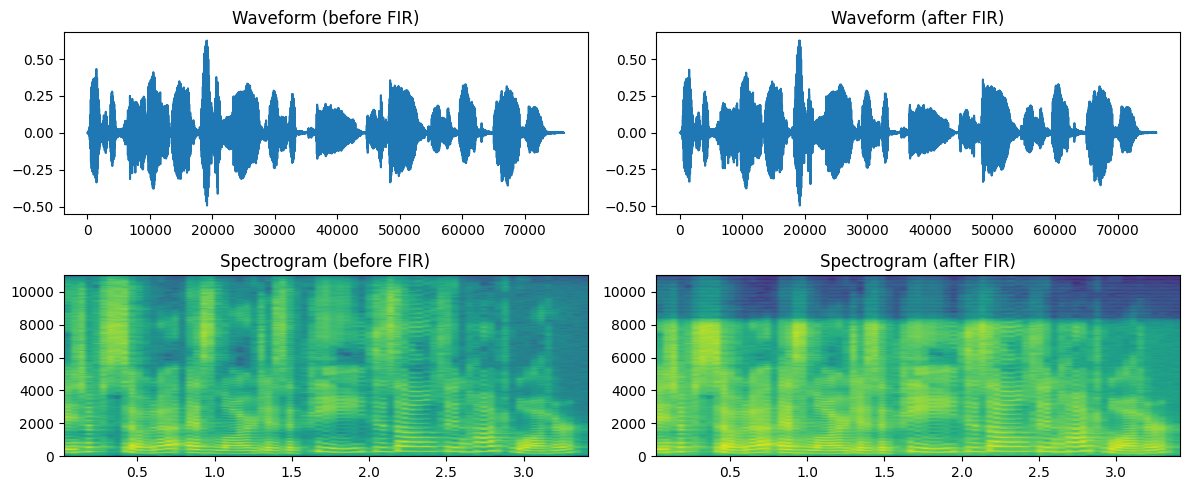

In [5]:
fir = signal.firwin(FIR_TAPS, FIR_CUTOFF, fs=SR)

def read_wav(path):
    sr, y = wavfile.read(path)
    assert sr == SR, f"unexpected sample rate {sr}"
    if y.ndim > 1: y = y.mean(1)
    return y.astype(np.float32) / 32768.0            # int16 -> [-1, 1]

def fir_filter(y):
    return signal.lfilter(fir, 1.0, y)

def to_spectrogram(y):
    _, _, Z = signal.stft(y, fs=SR, nperseg=N_FFT)   # Hann window, 50% overlap, zero-padded edges
    return np.abs(Z).T.astype(np.float32)           # (time steps, 1025)

specs, y_first = [], None
for i, (_, _, p) in enumerate(pairs):
    y = read_wav(p)
    if i == 0: y_first = y
    specs.append(to_spectrogram(fir_filter(y)))

MAX_FRAMES = max(s.shape[0] for s in specs)
N_BINS = specs[0].shape[1]
Y_all = np.zeros((len(specs), MAX_FRAMES, N_BINS), dtype=np.float32)       # zero padding
for i, s in enumerate(specs): Y_all[i, :len(s)] = s
del specs; gc.collect()

print("Y_all:", Y_all.shape, "(sentences, time steps, freq bins)")
print("amplitude range: max %.4f, mean %.6f" % (Y_all.max(), Y_all.mean()))
if Y_all.max() > 1: print("WARNING: amplitudes above 1 cannot be matched by a sigmoid output")

# Figure 1 of the paper: waveform and spectrogram before / after the FIR filter
fig, ax = plt.subplots(2, 2, figsize=(12, 5))
for col, (name, sig) in enumerate([("before FIR", y_first), ("after FIR", fir_filter(y_first))]):
    ax[0, col].plot(sig); ax[0, col].set_title(f"Waveform ({name})")
    ax[1, col].specgram(sig, NFFT=N_FFT, Fs=SR, noverlap=N_FFT // 2); ax[1, col].set_title(f"Spectrogram ({name})")
plt.tight_layout(); plt.show()

## 5. Postprocess: spectrogram -> wav
Inverse STFT (`scipy.signal.istft`; the predicted amplitude matrix has no phase, so phase is zero) followed by an inverse FIR filter, then saved with `scipy.io.wavfile`. The paper does not say how the inverse FIR filter is computed; here it is a regularised frequency-domain inverse (it also removes the filter's delay). The whole padded output is kept (no trimming).

In [6]:
def inverse_fir(y, h, eps=1e-2):
    n = int(2 ** np.ceil(np.log2(len(y) + len(h))))
    H = np.fft.rfft(h, n)
    Y = np.fft.rfft(y, n)
    x = np.fft.irfft(Y * np.conj(H) / (np.abs(H) ** 2 + eps), n)
    return x[:len(y)]

def spec_to_wav(spec, path, normalize=True):
    Z = spec.T.astype(np.complex64)                  # (1025, T), real-valued -> zero phase
    _, y = signal.istft(Z, fs=SR, nperseg=N_FFT)
    y = inverse_fir(y.astype(np.float64), fir)
    if normalize:                                     # needed to store as 16-bit wav without clipping
        y = y / (np.max(np.abs(y)) + 1e-12)
    wavfile.write(path, SR, (np.clip(y, -1, 1) * 32767).astype(np.int16))
    return y

# sanity check: the real magnitudes pushed through the same postprocessing (best this pipeline can do)
_ = spec_to_wav(Y_all[0], os.path.join(OUT_DIR, "ground_truth_reconstruction.wav"))

## 6. Train / dev split and test inputs

In [7]:
X_train, Y_train = X_all[:N_TRAIN], Y_all[:N_TRAIN]
X_dev,   Y_dev   = X_all[N_TRAIN:], Y_all[N_TRAIN:]
del Y_all; gc.collect()
n_dev = len(X_dev)

TEST_SENTENCE = "The quick brown fox jumps over the lazy dog."     # unseen text (any string)
test_ids = text_to_ids(TEST_SENTENCE)                              # same preprocessing as training
if len(test_ids) > MAX_TEXT_LEN: print("WARNING: test sentence is longer than the training maximum and will be cut")
X_test = pad_ids(test_ids, MAX_TEXT_LEN)[None]
X_trsent = X_train[:1]                                             # a training sentence, as a sanity check
X_eval = np.concatenate([X_dev, X_test, X_trsent])                 # rows: dev..., test, training sentence
I_TEST, I_TRSENT = n_dev, n_dev + 1
print("Training sentence:", texts[0])

# context for reading the loss values below (amplitudes are small, so MSE values are tiny)
print("dev MSE if we predict all zeros       : %.3e" % np.mean(Y_dev ** 2))
print("dev MSE if we predict the train mean  : %.3e" % np.mean((Y_dev - Y_train.mean(0, keepdims=True)) ** 2))

Training sentence: Bit of soda as large as a pea, dissolved in hot water.
dev MSE if we predict all zeros       : 2.368e-06
dev MSE if we predict the train mean  : 2.011e-06


## 7. Model A - SVR
One SVR "bank" per time step: a support-vector multi-regressor that maps the input text matrix to the 1025-value spectrum of that time step (linear kernel and polynomial kernel were tried in the paper; the polynomial kernel was kept). That is `T x 1025` separate SVRs trained on 200 samples. Equivalent to scikit-learn's `MultiOutputRegressor(SVR(kernel="poly"))` per time step; models are fitted and used for prediction inside parallel workers and then discarded, because storing 200,000+ fitted SVRs would not fit in memory. **This takes a while** (the paper also notes SVR training is too slow).

In [8]:
from sklearn.svm import SVR
from joblib import Parallel, delayed

def _fit_predict(Xtr, Ycols, Xev):
    out = np.empty((len(Xev), Ycols.shape[1]), dtype=np.float32)
    for j in range(Ycols.shape[1]):
        out[:, j] = SVR(kernel=SVR_KERNEL).fit(Xtr, Ycols[:, j]).predict(Xev)
    return out

Xtr_f, Xev_f = X_train.astype(np.float64), X_eval.astype(np.float64)
P_svr = np.zeros((len(X_eval), MAX_FRAMES, N_BINS), dtype=np.float32)
bin_chunks = np.array_split(np.arange(N_BINS), 32)

t0 = time.time()
for t in range(MAX_FRAMES):                                   # one SVR bank per time step
    res = Parallel(n_jobs=SVR_N_JOBS)(delayed(_fit_predict)(Xtr_f, Y_train[:, t, c], Xev_f) for c in bin_chunks)
    P_svr[:, t, :] = np.concatenate(res, axis=1)
    if t % 20 == 0: print(f"time step {t}/{MAX_FRAMES}  ({time.time()-t0:.0f}s)")

svr_dev_mse = np.mean((P_svr[:n_dev] - Y_dev) ** 2)
print("SVR dev MSE: %.3e | %.0fs" % (svr_dev_mse, time.time() - t0))
spec_to_wav(P_svr[I_TEST],   os.path.join(OUT_DIR, "svr.wav"))
spec_to_wav(P_svr[I_TRSENT], os.path.join(OUT_DIR, "trainsent_svr.wav"));

time step 0/109  (3s)
time step 20/109  (18s)
time step 40/109  (34s)
time step 60/109  (50s)
time step 80/109  (66s)
time step 100/109  (82s)
SVR dev MSE: 3.059e-05 | 88s


## 8. Model B - Simple neural network
Input layer = embedded text vector; one fully-connected hidden layer with as many neurons as the input; output layer = the spectrogram stretched into a 1D vector (T x 1025), sigmoid activation, reshaped back afterwards. Mini-batch 10.

In [9]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.random.set_seed(SEED)

def make_progress(t_start):
    return keras.callbacks.LambdaCallback(on_epoch_end=lambda e, l:
        print(f"epoch {e+1}/{EPOCHS}  loss {l['loss']:.3e}  val {l['val_loss']:.3e}  ({time.time()-t_start:.0f}s)")
        if (e + 1) % 10 == 0 or e == 0 else None)

nn_in = keras.Input((MAX_TEXT_LEN,), dtype="int32")
x = layers.Embedding(VOCAB, EMB_DIM_NN)(nn_in)
x = layers.Flatten()(x)                                                   # input layer: the whole embedded vector
x = layers.Dense(MAX_TEXT_LEN * EMB_DIM_NN, activation="sigmoid")(x)     # hidden: same size as the input
x = layers.Dense(MAX_FRAMES * N_BINS, activation="sigmoid")(x)            # output: stretched 1D spectrogram
nn_out = layers.Reshape((MAX_FRAMES, N_BINS))(x)
nn_model = keras.Model(nn_in, nn_out)
nn_model.compile(optimizer="adam", loss="mse")
nn_model.summary()

t0 = time.time()
nn_hist = nn_model.fit(X_train, Y_train, validation_data=(X_dev, Y_dev), batch_size=BATCH_SIZE,
                       epochs=EPOCHS, verbose=0, callbacks=[make_progress(t0)])
print("NN train loss %.3e | dev loss %.3e | %.0fs" % (nn_hist.history["loss"][-1], nn_hist.history["val_loss"][-1], time.time() - t0))

P_nn = nn_model.predict(X_eval, verbose=0)
spec_to_wav(P_nn[I_TEST],   os.path.join(OUT_DIR, "nn.wav"))
spec_to_wav(P_nn[I_TRSENT], os.path.join(OUT_DIR, "trainsent_nn.wav"));

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 88)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 88, 4)          │           292 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 352)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 352)            │       124,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 111725)         │    39,438,925 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 109, 1025)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 39,563,473 (150.92 MB)

 Trainable params: 39,563,473 (150.92 MB)

 Non-trainable params: 0 (0.00 B)

epoch 1/100  loss 1.238e-01  val 2.371e-02  (4s)
epoch 10/100  loss 1.070e-04  val 9.639e-05  (7s)
epoch 20/100  loss 5.449e-05  val 5.077e-05  (10s)
epoch 30/100  loss 3.491e-05  val 3.312e-05  (13s)
epoch 40/100  loss 2.507e-05  val 2.407e-05  (17s)
epoch 50/100  loss 1.929e-05  val 1.867e-05  (21s)
epoch 60/100  loss 1.555e-05  val 1.516e-05  (24s)
epoch 70/100  loss 1.296e-05  val 1.272e-05  (27s)
epoch 80/100  loss 1.110e-05  val 1.094e-05  (31s)
epoch 90/100  loss 9.694e-06  val 9.602e-06  (34s)
epoch 100/100  loss 8.611e-06  val 8.566e-06  (38s)
NN train loss 8.611e-06 | dev loss 8.566e-06 | 38s


## 9. Model C - Seq2Seq with attention
* Encoder: embedding (output size = number of spectrogram bins, i.e. aligned with the output wave matrix) -> bidirectional LSTM (2 x 256 = 512 latent dims)
* Decoder: LSTM (512) whose initial hidden and cell state are the encoder's states, plus attention over the encoder outputs
* Training: two inputs (text, spectrogram); the target is the spectrogram **one time step later** than the input
* Generation: the encoder reads the whole sentence; the decoder starts from the **first time step of the spectrogram** and generates the rest, one frame at a time. For the unseen test sentence there is no audio, so the first frame of the first training clip is used as the seed.

In [10]:
LATENT = 512
enc_in = keras.Input((MAX_TEXT_LEN,), dtype="int32")
emb = layers.Embedding(VOCAB, N_BINS)(enc_in)
enc_bi = layers.Bidirectional(layers.LSTM(LATENT // 2, return_sequences=True, return_state=True))
enc_seq, fh, fc, bh, bc = enc_bi(emb)
enc_h = layers.Concatenate()([fh, bh]); enc_c = layers.Concatenate()([fc, bc])

dec_in = keras.Input((None, N_BINS))
dec_lstm = layers.LSTM(LATENT, return_sequences=True, return_state=True)
attn = layers.Attention()
dec_concat = layers.Concatenate()
dec_dense = layers.Dense(N_BINS)

dec_seq, _, _ = dec_lstm(dec_in, initial_state=[enc_h, enc_c])
ctx = attn([dec_seq, enc_seq])
dec_out = dec_dense(dec_concat([dec_seq, ctx]))

s2s = keras.Model([enc_in, dec_in], dec_out)
s2s.compile(optimizer="adam", loss="mse")

t0 = time.time()
s2s_hist = s2s.fit([X_train, Y_train[:, :-1]], Y_train[:, 1:],                   # output = input shifted by one step
                   validation_data=([X_dev, Y_dev[:, :-1]], Y_dev[:, 1:]),
                   batch_size=BATCH_SIZE, epochs=EPOCHS, verbose=0, callbacks=[make_progress(t0)])
print("Seq2Seq train loss %.3e | dev loss %.3e | %.0fs  (teacher-forced)" %
      (s2s_hist.history["loss"][-1], s2s_hist.history["val_loss"][-1], time.time() - t0))

# ---- generation models (decoder runs one step at a time) ----
enc_model = keras.Model(enc_in, [enc_seq, enc_h, enc_c])
step_frame = keras.Input((1, N_BINS))
step_enc   = keras.Input((MAX_TEXT_LEN, LATENT))
step_h, step_c = keras.Input((LATENT,)), keras.Input((LATENT,))
o, h, c = dec_lstm(step_frame, initial_state=[step_h, step_c])
y_step = dec_dense(dec_concat([o, attn([o, step_enc])]))
dec_step = keras.Model([step_frame, step_enc, step_h, step_c], [y_step, h, c])

def s2s_generate(x_ids, first_frame, n_frames=MAX_FRAMES):
    es, h, c = [tf.constant(a) for a in enc_model.predict(x_ids, verbose=0)]
    frame = tf.constant(np.asarray(first_frame, dtype=np.float32).reshape(1, 1, N_BINS))
    out = [frame.numpy()[0, 0]]
    for _ in range(n_frames - 1):
        frame, h, c = dec_step([frame, es, h, c], training=False)
        out.append(frame.numpy()[0, 0])
    return np.stack(out)

# free-running dev loss: the decoder only gets the first frame (this is the paper's validation procedure)
free_mse = np.mean([np.mean((s2s_generate(X_dev[i:i+1], Y_dev[i, 0]) - Y_dev[i]) ** 2) for i in range(N_FREE_DEV)])
print("Seq2Seq free-running dev MSE (first %d dev sentences): %.3e" % (N_FREE_DEV, free_mse))

P_s2s_test   = s2s_generate(X_test, Y_train[0, 0])         # seed: first frame of the first training clip
P_s2s_trsent = s2s_generate(X_trsent, Y_train[0, 0])       # seed: its own first frame
spec_to_wav(P_s2s_test,   os.path.join(OUT_DIR, "seq2seq_attention.wav"))
spec_to_wav(P_s2s_trsent, os.path.join(OUT_DIR, "trainsent_seq2seq_attention.wav"))
spec_to_wav(Y_train[0],   os.path.join(OUT_DIR, "trainsent_ground_truth.wav"));

epoch 1/100  loss 1.729e-05  val 7.254e-06  (8s)
epoch 10/100  loss 3.147e-06  val 3.377e-06  (15s)
epoch 20/100  loss 2.512e-06  val 2.784e-06  (25s)
epoch 30/100  loss 2.262e-06  val 2.533e-06  (34s)
epoch 40/100  loss 2.152e-06  val 2.445e-06  (42s)
epoch 50/100  loss 2.072e-06  val 2.342e-06  (50s)
epoch 60/100  loss 2.042e-06  val 2.292e-06  (59s)
epoch 70/100  loss 2.000e-06  val 2.234e-06  (67s)
epoch 80/100  loss 1.997e-06  val 2.205e-06  (76s)
epoch 90/100  loss 1.985e-06  val 2.216e-06  (84s)
epoch 100/100  loss 1.909e-06  val 2.127e-06  (93s)
Seq2Seq train loss 1.909e-06 | dev loss 2.127e-06 | 93s  (teacher-forced)
Seq2Seq free-running dev MSE (first 5 dev sentences): 2.419e-06


## 10. Training loss curves and predicted spectrograms
(Paper Figure 6: training loss of the NN and the Seq2Seq model. Here the x-axis is epochs; 100 epochs = 2000 iterations.)

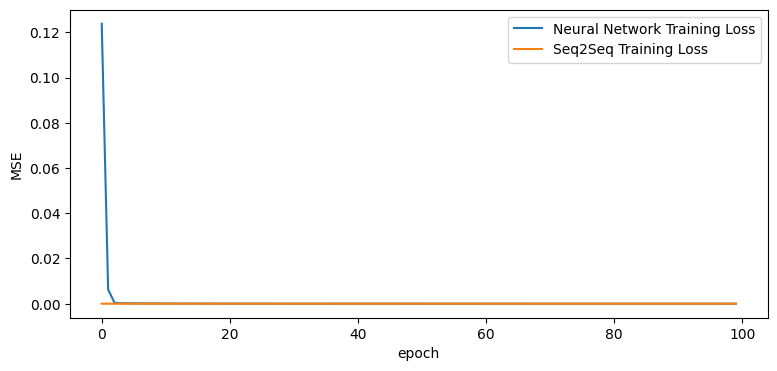

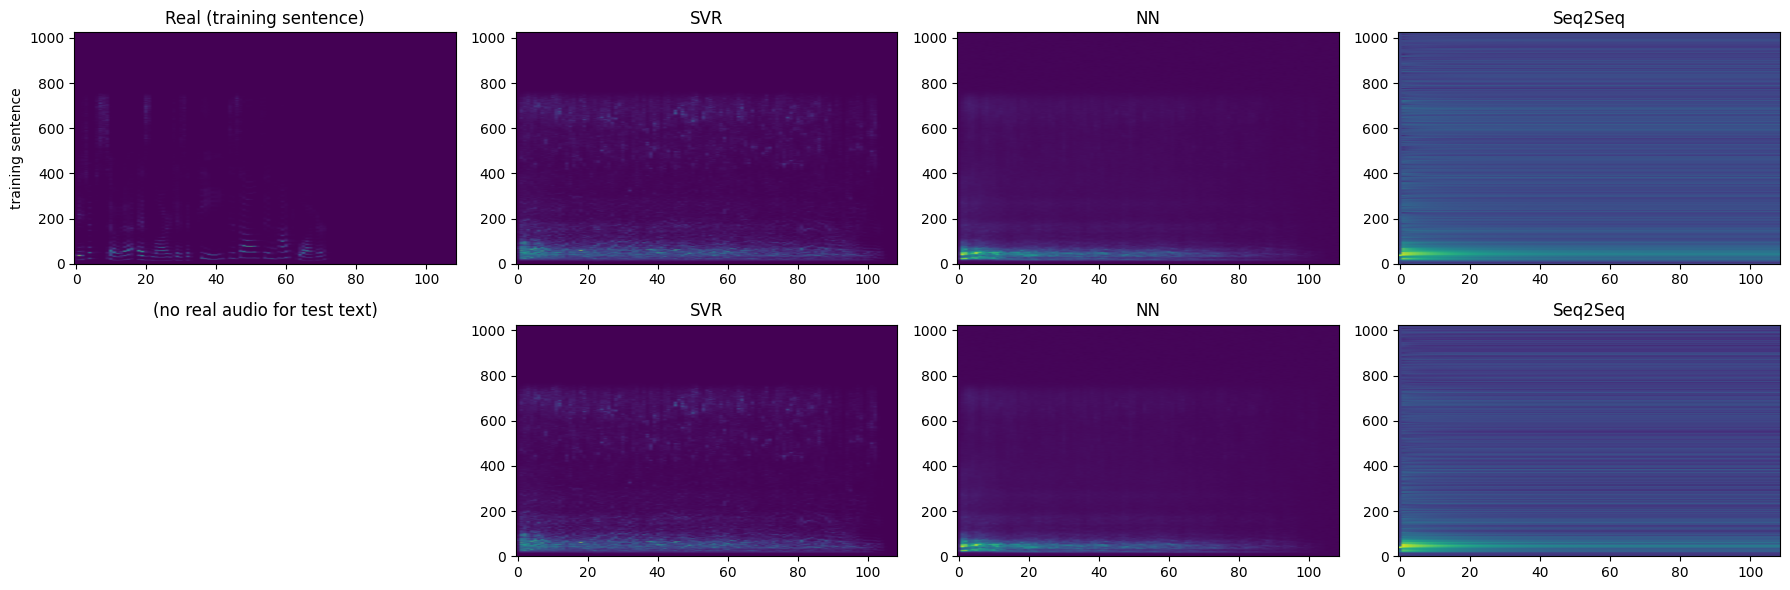

In [11]:
plt.figure(figsize=(9, 4))
plt.plot(nn_hist.history["loss"], label="Neural Network Training Loss")
plt.plot(s2s_hist.history["loss"], label="Seq2Seq Training Loss")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()

fig, ax = plt.subplots(2, 4, figsize=(18, 6))
panels = [("Real (training sentence)", Y_train[0]), ("SVR", P_svr[I_TRSENT]), ("NN", P_nn[I_TRSENT]), ("Seq2Seq", P_s2s_trsent),
          ("(no real audio for test text)", None), ("SVR", P_svr[I_TEST]), ("NN", P_nn[I_TEST]), ("Seq2Seq", P_s2s_test)]
for a, (name, sp) in zip(ax.ravel(), panels):
    if sp is None: a.axis("off"); a.set_title(name); continue
    a.imshow(sp.T, origin="lower", aspect="auto"); a.set_title(name)
ax[0, 0].set_ylabel("training sentence"); ax[1, 0].set_ylabel("unseen test sentence")
plt.tight_layout(); plt.show()

## 11. Listen to the results
First four: the unseen test sentence (`ground_truth_reconstruction` is a real clip run through the same zero-phase postprocessing). Last four: a training sentence.

In [12]:
from IPython.display import Audio, display
for name in ["ground_truth_reconstruction", "svr", "nn", "seq2seq_attention",
             "trainsent_ground_truth", "trainsent_svr", "trainsent_nn", "trainsent_seq2seq_attention"]:
    print(name); display(Audio(os.path.join(OUT_DIR, name + ".wav")))

ground_truth_reconstruction


svr


nn


seq2seq_attention


trainsent_ground_truth


trainsent_svr


trainsent_nn


trainsent_seq2seq_attention


## 12. Evaluation - Mean Opinion Score (MOS)
Naturalness rated by listeners (Table 1 of the paper: Excellent 5, Good 4, Fair 3, Poor 2, Bad 1). Enter **your listeners' real ratings** below, one number per listener per model. Reference values reported in the paper: SVR 1.0, NN 1.7, Seq2Seq 2.5 (10 Stanford students); Tacotron 3.82 (quoted from the Tacotron paper).

,MOS,Std,N listeners
SVR,1.0,0.000000,5
NN,1.4,0.489898,5
Seq2Seq,1.6,0.489898,5


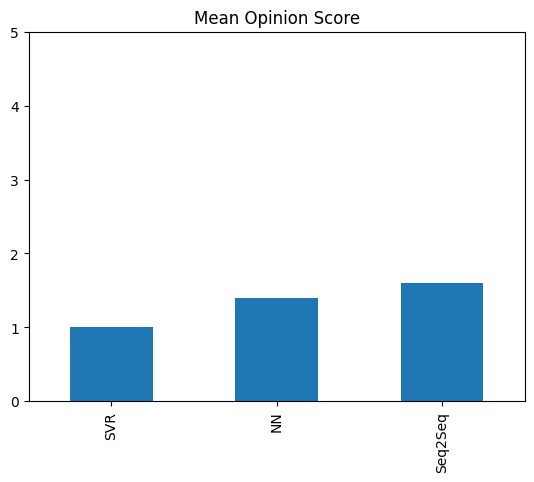

In [13]:
import pandas as pd
from IPython.display import display

# one rating (1-5) per listener; leave empty until the listening survey is done
ratings = {
    "SVR":     [1,1,1,1,1],
    "NN":      [1,1,1,1,2],
    "Seq2Seq": [2,1,1,2,1],
}

if any(len(v) for v in ratings.values()):
    mos = pd.DataFrame({"MOS": {k: np.mean(v) if v else np.nan for k, v in ratings.items()},
                        "Std": {k: np.std(v) if v else np.nan for k, v in ratings.items()},
                        "N listeners": {k: len(v) for k, v in ratings.items()}})
    display(mos)
    mos["MOS"].plot.bar(ylim=(0, 5), title="Mean Opinion Score"); plt.show()
else:
    print("No ratings entered yet - fill in `ratings` after the listening survey.")